# DeMa, Decision Transformer and CQL

HalfCheetah target: 12,000. AntMaze targets: 538 and 438.

3 training runs × 100 tests per target. SD: variation between run averages. Middle reward: middle of the three run medians.

In [ ]:
!pip install -q numpy==2.5.3 pandas==3.0.6 matplotlib==3.11.2 wandb==0.31.0

Place `results.zip` in the input files or `assets/`.

In [1]:
from pathlib import Path
import json
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

archive = Path("assets/results.zip")
if not archive.exists():
    archive = next(Path("/kaggle/input").rglob("results.zip"))
with zipfile.ZipFile(archive) as f:
    f.extractall("results")
figures = Path("figures/main")
figures.mkdir(parents=True, exist_ok=True)
seeds = [42, 43, 44]
colors = {"DT": "#147BE8", "DeMa": "#E52666", "CQL": "#15945B",
          "SSM": "#7753D6", "DeMa + SER": "#F09500"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12,
                     "text.color": "black", "axes.labelcolor": "black",
                     "xtick.color": "black", "ytick.color": "black",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "savefig.facecolor": "white"})

def load(prefix, seed):
    return json.loads((Path("results") / f"{prefix}_seed{seed}.json").read_text())

def evaluations(prefix, model, target):
    rows = []
    for seed in seeds:
        data = load(prefix, seed)
        row = data["evaluation"] if model == "CQL" else data["models"][model]["evaluations"][str(float(target))]
        scores = np.asarray(row["return_scores"])
        assert len(scores) == row["rollouts"] == 100
        assert np.isfinite(scores).all()
        assert np.isclose(scores.mean(), row["return_mean"])
        assert np.isclose(np.median(scores), row["return_median"])
        rows.append(row)
    return rows

def summary(label, rows, target, maze=False):
    means = [r["return_mean"] for r in rows]
    result = {"Model": label, "Target": target,
              "Average reward": np.mean(means), "SD": np.std(means, ddof=1),
              "Middle reward": np.median([r["return_median"] for r in rows])}
    if maze:
        result["Goal arrival (%)"] = sum(np.count_nonzero(np.asarray(r["return_scores"]) > 0) for r in rows) / 3
    return result

def table(rows):
    display(pd.DataFrame(rows).style.format(precision=1, thousands=","))

def save(fig, name):
    fig.savefig(figures / name, dpi=400)
    plt.show()
    plt.close(fig)

def bars(ax, labels, values, palette, title, ylabel, percent=False, samples=None):
    ax.bar(range(len(labels)), values, color=palette, width=0.58)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_title(title, fontweight="bold", pad=16)
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#DBE5EF", linewidth=0.7)
    ax.set_ylim(0, 112 if percent else max(values) * 1.29)
    if percent:
        ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
    for i, value in enumerate(values):
        height = max(value, max(samples[i])) if samples is not None else value
        ax.annotate(f"{value:.1f}%" if percent else f"{value:,.0f}",
                    (i, height), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=13, fontweight="bold")
    if samples is not None:
        for i, points in enumerate(samples):
            ax.scatter(i + np.linspace(-0.12, 0.12, len(points)), points,
                       s=26, facecolor="white", edgecolor="black", zorder=3)
        ax.set_ylim(0, max(max(points) for points in samples) * 1.30)

def losses(cases, name):
    fig, axes = plt.subplots((len(cases) + 1) // 2, 2, figsize=(11, 3.7 * ((len(cases) + 1) // 2)),
                             layout="constrained", squeeze=False)
    for ax, (title, prefix, model) in zip(axes.flat, cases):
        histories = [load(prefix, seed)["models"][model]["loss_history"] for seed in seeds]
        for key, label, color, line in [("loss", "Training", "#147BE8", "-"),
                                         ("validation_loss", "Validation", "#D87700", "--")]:
            steps = sorted(set.intersection(*[{p["step"] for p in h if key in p} for h in histories]))
            values = np.mean([[next(p[key] for p in h if p["step"] == step) for step in steps] for h in histories], axis=0)
            choose = np.asarray(steps) >= 10000
            ax.plot(np.asarray(steps)[choose] / 1000, values[choose], color=color,
                    linestyle=line, linewidth=2.4, label=label)
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Training updates (thousands)")
        ax.set_ylabel("Action prediction loss")
        ax.set_xlim(10, 100)
        ax.set_xticks([10, 50, 100])
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color="#DBE5EF", linewidth=0.7)
    for row in axes:
        visible = [ax for ax in row if ax.has_data()]
        top = max(ax.get_ylim()[1] for ax in visible)
        for ax in visible:
            ax.set_ylim(0, top * 1.10)
    for ax in list(axes.flat)[len(cases):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False, fontsize=11)
    save(fig, name)


## Control results

Higher reward and goal arrival are better. CQL has no reward target.

,Model,Target,Average reward,SD,Middle reward
0,DT,"12,000","10,291.1","2,349.5","13,567.7"
1,DeMa,"12,000","12,553.8",383.5,"12,914.8"
2,CQL,None,519.2,552.3,507.0


,Model,Target,Average reward,SD,Middle reward,Goal arrival (%)
0,DT,538,384.4,40.3,479.0,81.0
1,DeMa,538,369.9,28.1,464.0,81.0
2,DT,438,388.4,28.6,479.5,82.7
3,DeMa,438,385.0,19.1,466.0,82.7


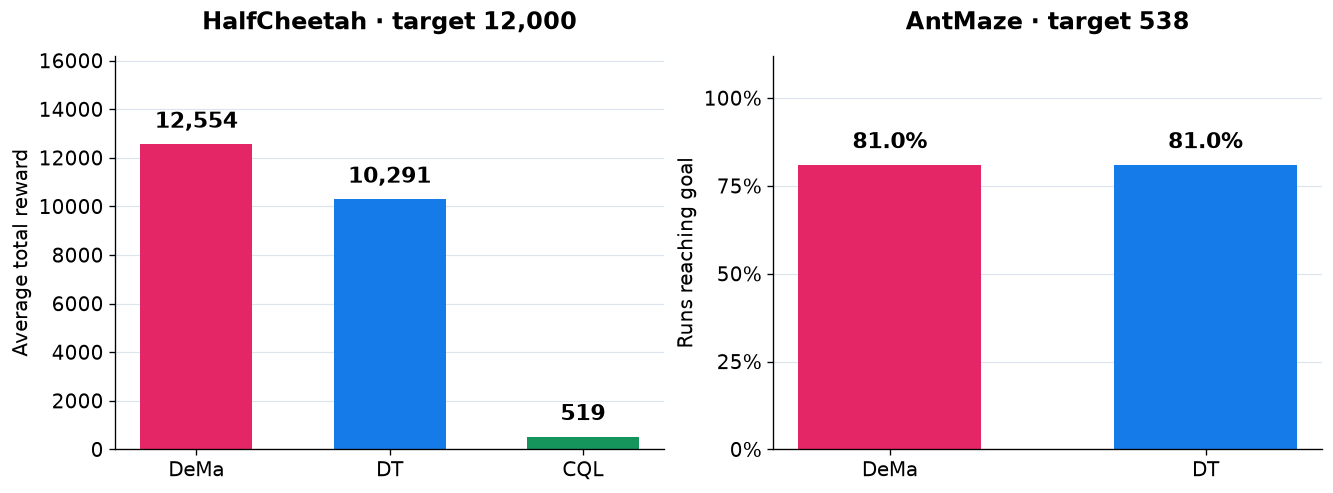

DeMa: 22.0% higher average running reward; equal AntMaze goal arrival.


In [2]:
hc = {"DT": evaluations("final_dt", "Decision Transformer", 12000),
      "DeMa": evaluations("final_dema", "DeMa", 12000),
      "CQL": evaluations("cql_d3rlpy_fixed_halfcheetah", "CQL", None)}
maze = {}
for target in [538, 438]:
    for label, prefix, model in [("DT", "antmaze_dt", "Decision Transformer"), ("DeMa", "antmaze_dema", "DeMa")]:
        maze[label, target] = evaluations(prefix, model, target)
table([summary(label, rows, "None" if label == "CQL" else 12000) for label, rows in hc.items()])
table([summary(label, maze[label, target], target, True) for target in [538, 438] for label in ["DT", "DeMa"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
labels = ["DeMa", "DT", "CQL"]
bars(axes[0], labels, [np.mean([r["return_mean"] for r in hc[m]]) for m in labels],
     [colors[m] for m in labels], "HalfCheetah · target 12,000", "Average total reward")
labels = ["DeMa", "DT"]
goals = [summary(m, maze[m, 538], 538, True)["Goal arrival (%)"] for m in labels]
bars(axes[1], labels, goals, [colors[m] for m in labels], "AntMaze · target 538", "Runs reaching goal", True)
save(fig, "reward.png")
gain = 100 * (np.mean([r["return_mean"] for r in hc["DeMa"]]) / np.mean([r["return_mean"] for r in hc["DT"]]) - 1)
print(f"DeMa: {gain:.1f}% higher average running reward; equal AntMaze goal arrival.")

## Training and validation loss

Lower loss means closer action prediction. Curves average three training runs from 10,000 updates.

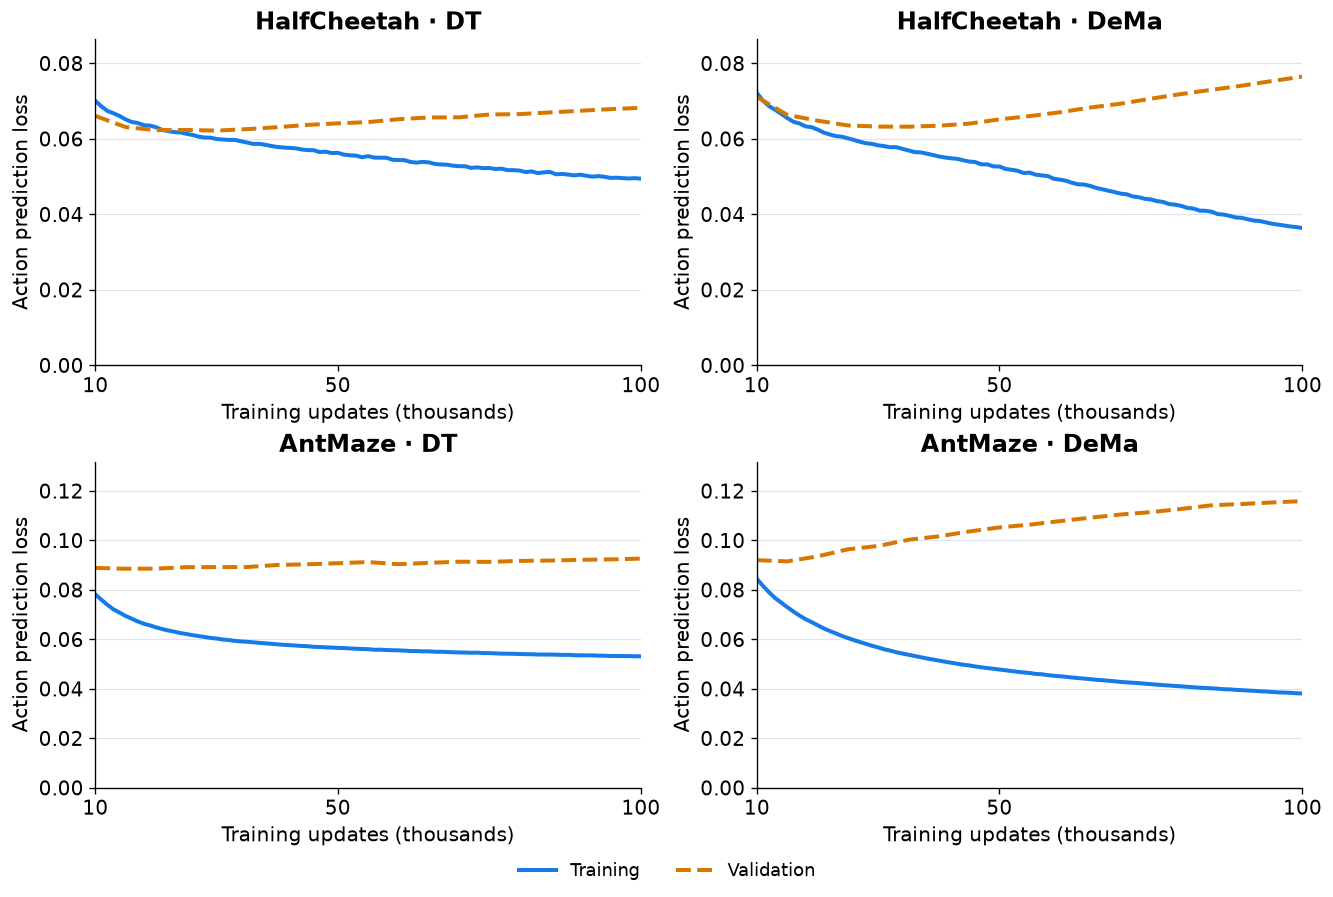

In [3]:
losses([("HalfCheetah · DT", "final_dt", "Decision Transformer"),
        ("HalfCheetah · DeMa", "final_dema", "DeMa"),
        ("AntMaze · DT", "antmaze_dt", "Decision Transformer"),
        ("AntMaze · DeMa", "antmaze_dema", "DeMa")], "loss.png")

## Results across training runs

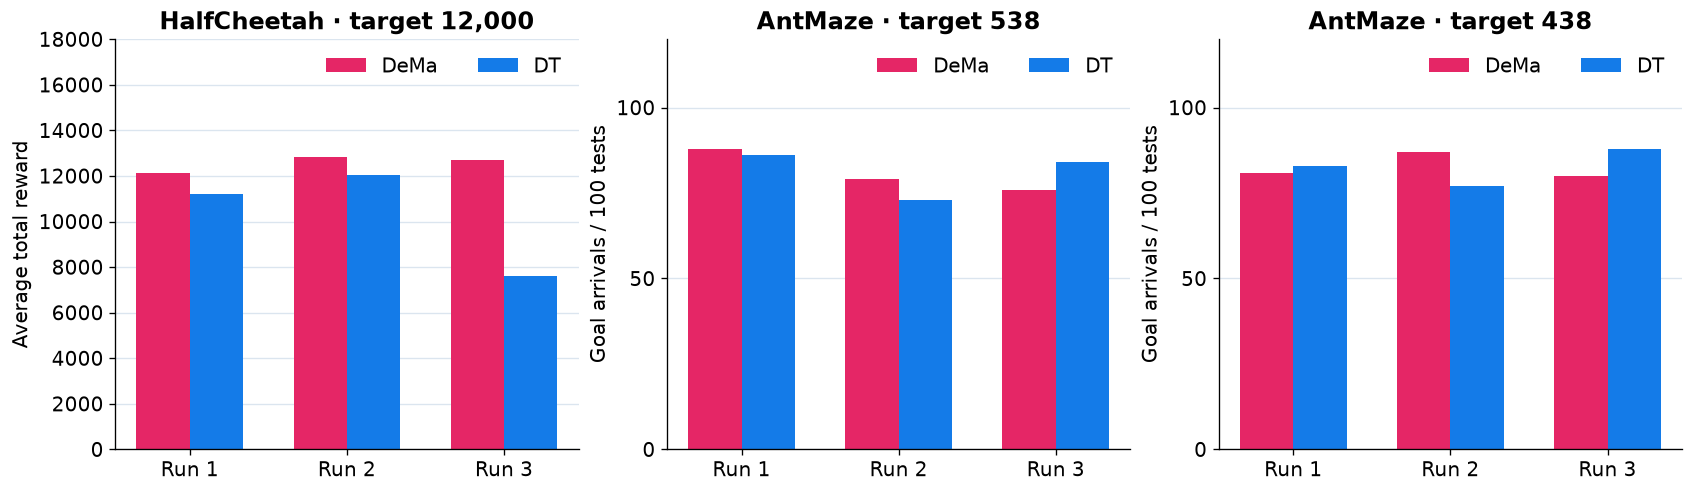

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
x = np.arange(3)
for i, label in enumerate(["DeMa", "DT"]):
    axes[0].bar(x + (i - 0.5) * 0.34, [r["return_mean"] for r in hc[label]],
                width=0.34, label=label, color=colors[label])
    for ax, target in zip(axes[1:], [538, 438]):
        counts = [np.count_nonzero(np.asarray(r["return_scores"]) > 0) for r in maze[label, target]]
        ax.bar(x + (i - 0.5) * 0.34, counts, width=0.34, label=label, color=colors[label])
        ax.set_ylim(0, 120)
        ax.set_yticks([0, 50, 100])
        ax.set_ylabel("Goal arrivals / 100 tests")
        ax.set_title(f"AntMaze · target {target}", fontweight="bold")
axes[0].set_title("HalfCheetah · target 12,000", fontweight="bold")
axes[0].set_ylabel("Average total reward")
axes[0].set_ylim(0, 18000)
for ax in axes:
    ax.set_xticks(x, ["Run 1", "Run 2", "Run 3"])
    ax.legend(frameon=False, ncol=2, loc="upper right")
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#DBE5EF")
save(fig, "runs.png")

## Reward distribution

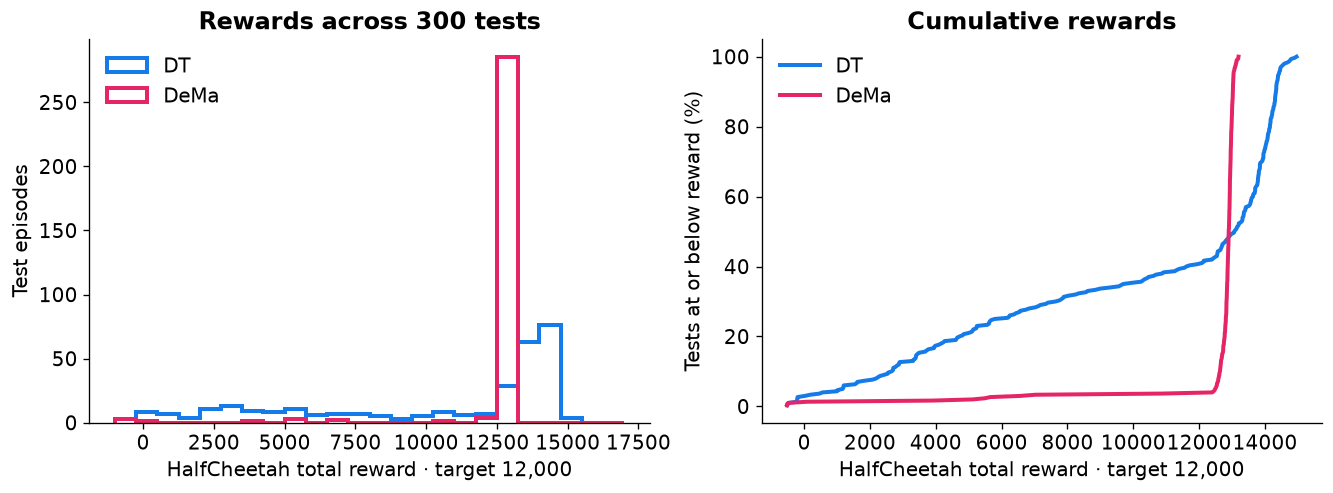

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for label in ["DT", "DeMa"]:
    scores = np.concatenate([r["return_scores"] for r in hc[label]])
    axes[0].hist(scores, bins=np.linspace(-1000, 17000, 25), histtype="step", linewidth=2.4, color=colors[label], label=label)
    values = np.sort(scores)
    axes[1].plot(values, 100 * np.arange(1, len(values) + 1) / len(values), color=colors[label], linewidth=2.4, label=label)
axes[0].set_ylabel("Test episodes")
axes[0].set_title("Rewards across 300 tests", fontweight="bold")
axes[1].set_ylabel("Tests at or below reward (%)")
axes[1].set_title("Cumulative rewards", fontweight="bold")
for ax in axes:
    ax.set_xlabel("HalfCheetah total reward · target 12,000")
    ax.legend(frameon=False)
save(fig, "distribution.png")

## Model size and recorded speed

Timing comes from simulator evaluations of three trained versions. DeMa’s control gain comes with a larger model and lower measured speed.

,Model,Parameters,Predictions / second,Speed SD
0,DT,"599,302",484.7,3.3
1,DeMa,"750,598",211.9,5.1
2,CQL,"691,218","1,866.7",38.8


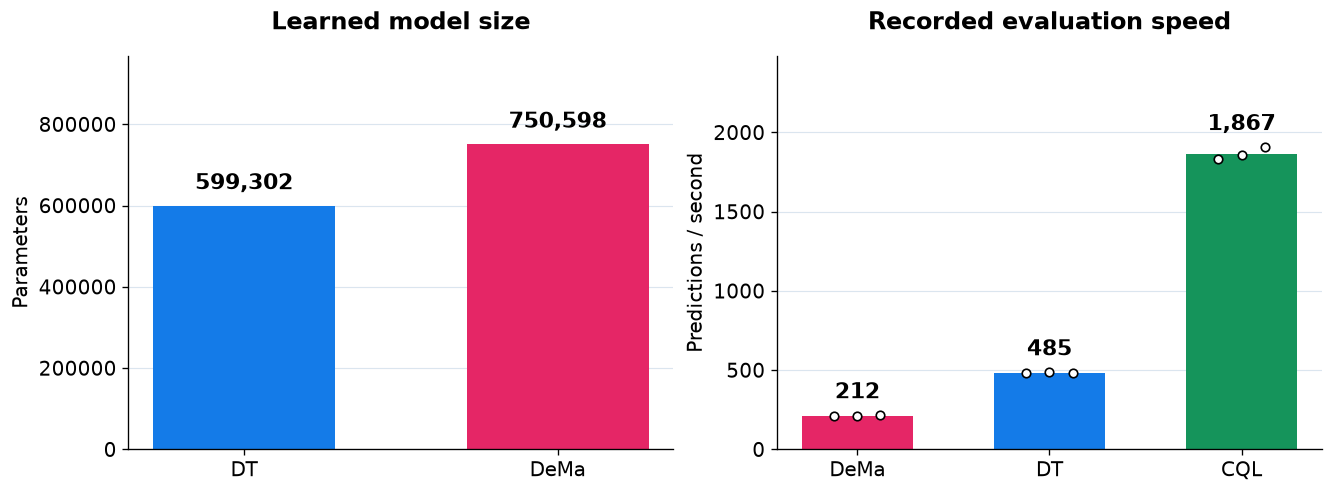

In [6]:
cost = []
for label, rows in hc.items():
    speed = [r["decisions_per_second"] for r in rows]
    cost.append({"Model": label, "Parameters": rows[0]["parameters"],
                 "Predictions / second": np.mean(speed), "Speed SD": np.std(speed, ddof=1)})
table(cost)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
labels = ["DT", "DeMa"]
bars(axes[0], labels, [hc[m][0]["parameters"] for m in labels], [colors[m] for m in labels], "Learned model size", "Parameters")
labels = ["DeMa", "DT", "CQL"]
speed = [[r["decisions_per_second"] for r in hc[m]] for m in labels]
bars(axes[1], labels, [np.mean(v) for v in speed], [colors[m] for m in labels], "Recorded evaluation speed", "Predictions / second", samples=speed)
save(fig, "cost.png")

## Control quality and speed

Filled circles: averages. Open circles: three training runs. Normalized reward: 0 at the random reference, 100 at the dataset-average reference.

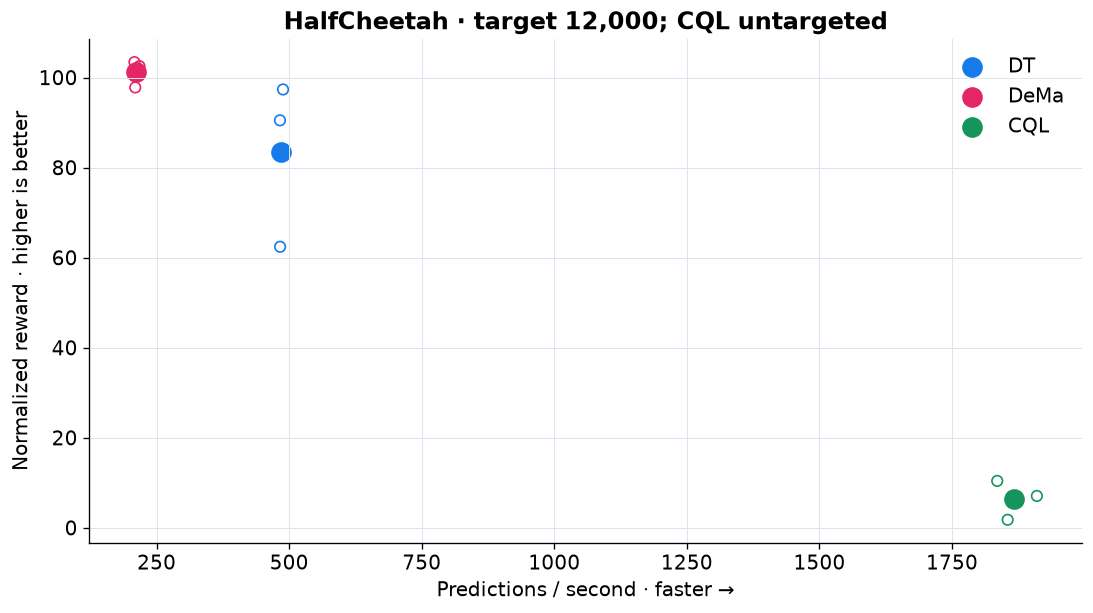

In [7]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for label in ["DT", "DeMa", "CQL"]:
    speeds = [r["decisions_per_second"] for r in hc[label]]
    scores = [r["normalized_return"] for r in hc[label]]
    ax.scatter(speeds, scores, s=40, facecolors="none", edgecolors=colors[label])
    ax.scatter(np.mean(speeds), np.mean(scores), s=130, color=colors[label], label=label)
ax.set_xlabel("Predictions / second · faster →")
ax.set_ylabel("Normalized reward · higher is better")
ax.set_title("HalfCheetah · target 12,000; CQL untargeted", fontweight="bold")
ax.legend(frameon=False)
ax.grid(color="#DBE5EF", linewidth=0.6)
save(fig, "quality_speed.png")

## W&B histories

In [8]:
names = [f"{prefix}_seed{seed}" for prefix in ["final_dt", "final_dema", "antmaze_dt", "antmaze_dema", "cql_d3rlpy_fixed_halfcheetah"] for seed in seeds]
logs = {}
if os.environ.get("WANDB_API_KEY"):
    import wandb
    api = wandb.Api(timeout=30)
    entity = os.environ.get("WANDB_ENTITY") or api.default_entity
    project = os.environ.get("WANDB_PROJECT", "dema-vs-dt")
    for run in api.runs(f"{entity}/{project}"):
        if run.name in names:
            logs[run.name] = list(run.scan_history(page_size=200))
    print(f"Loaded {len(logs)} run histories")